# Text Representation

**Completed lab solution.** Original instructions: [NLP_Lab5](https://github.com/MohammedMosuily/NLP_Lab5).

    Run the cells from top to bottom. Results below were generated by executing this notebook. The `dataset` folder contains the original data needed by this lab. Missing Python packages are installed by the setup cell; pretrained model downloads need internet on their first run. Random seeds are fixed where supported.

In [1]:
# Install only missing dependencies into the active Jupyter Python environment.
import importlib.util, subprocess, sys, os, random
from pathlib import Path
packages = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib', 'sklearn': 'scikit-learn', 'nltk': 'nltk', 'gensim': 'gensim'}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['USE_TF'] = '0'  # Transformers examples use PyTorch.
os.environ['USE_FLAX'] = '0'
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, HTML
random.seed(42)
np.random.seed(42)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.max_columns', 10)
DATA = Path('dataset')
assert DATA.exists() or 5 in (7, 8, 9), 'Open this notebook from its Lab folder.'

Text representation in NLP means converting text into a numerical form that a machine learning model can understand and process.

## What is Embedding?

Embeddings in NLP is a technique where individual words are represented as real-valued vectors and captures inter-word semantics.


In this notebook, We going to intreduce 2 techniques for embedding. These techniques will be used for a machine learning models such as SVM, Random forest, ... ect.

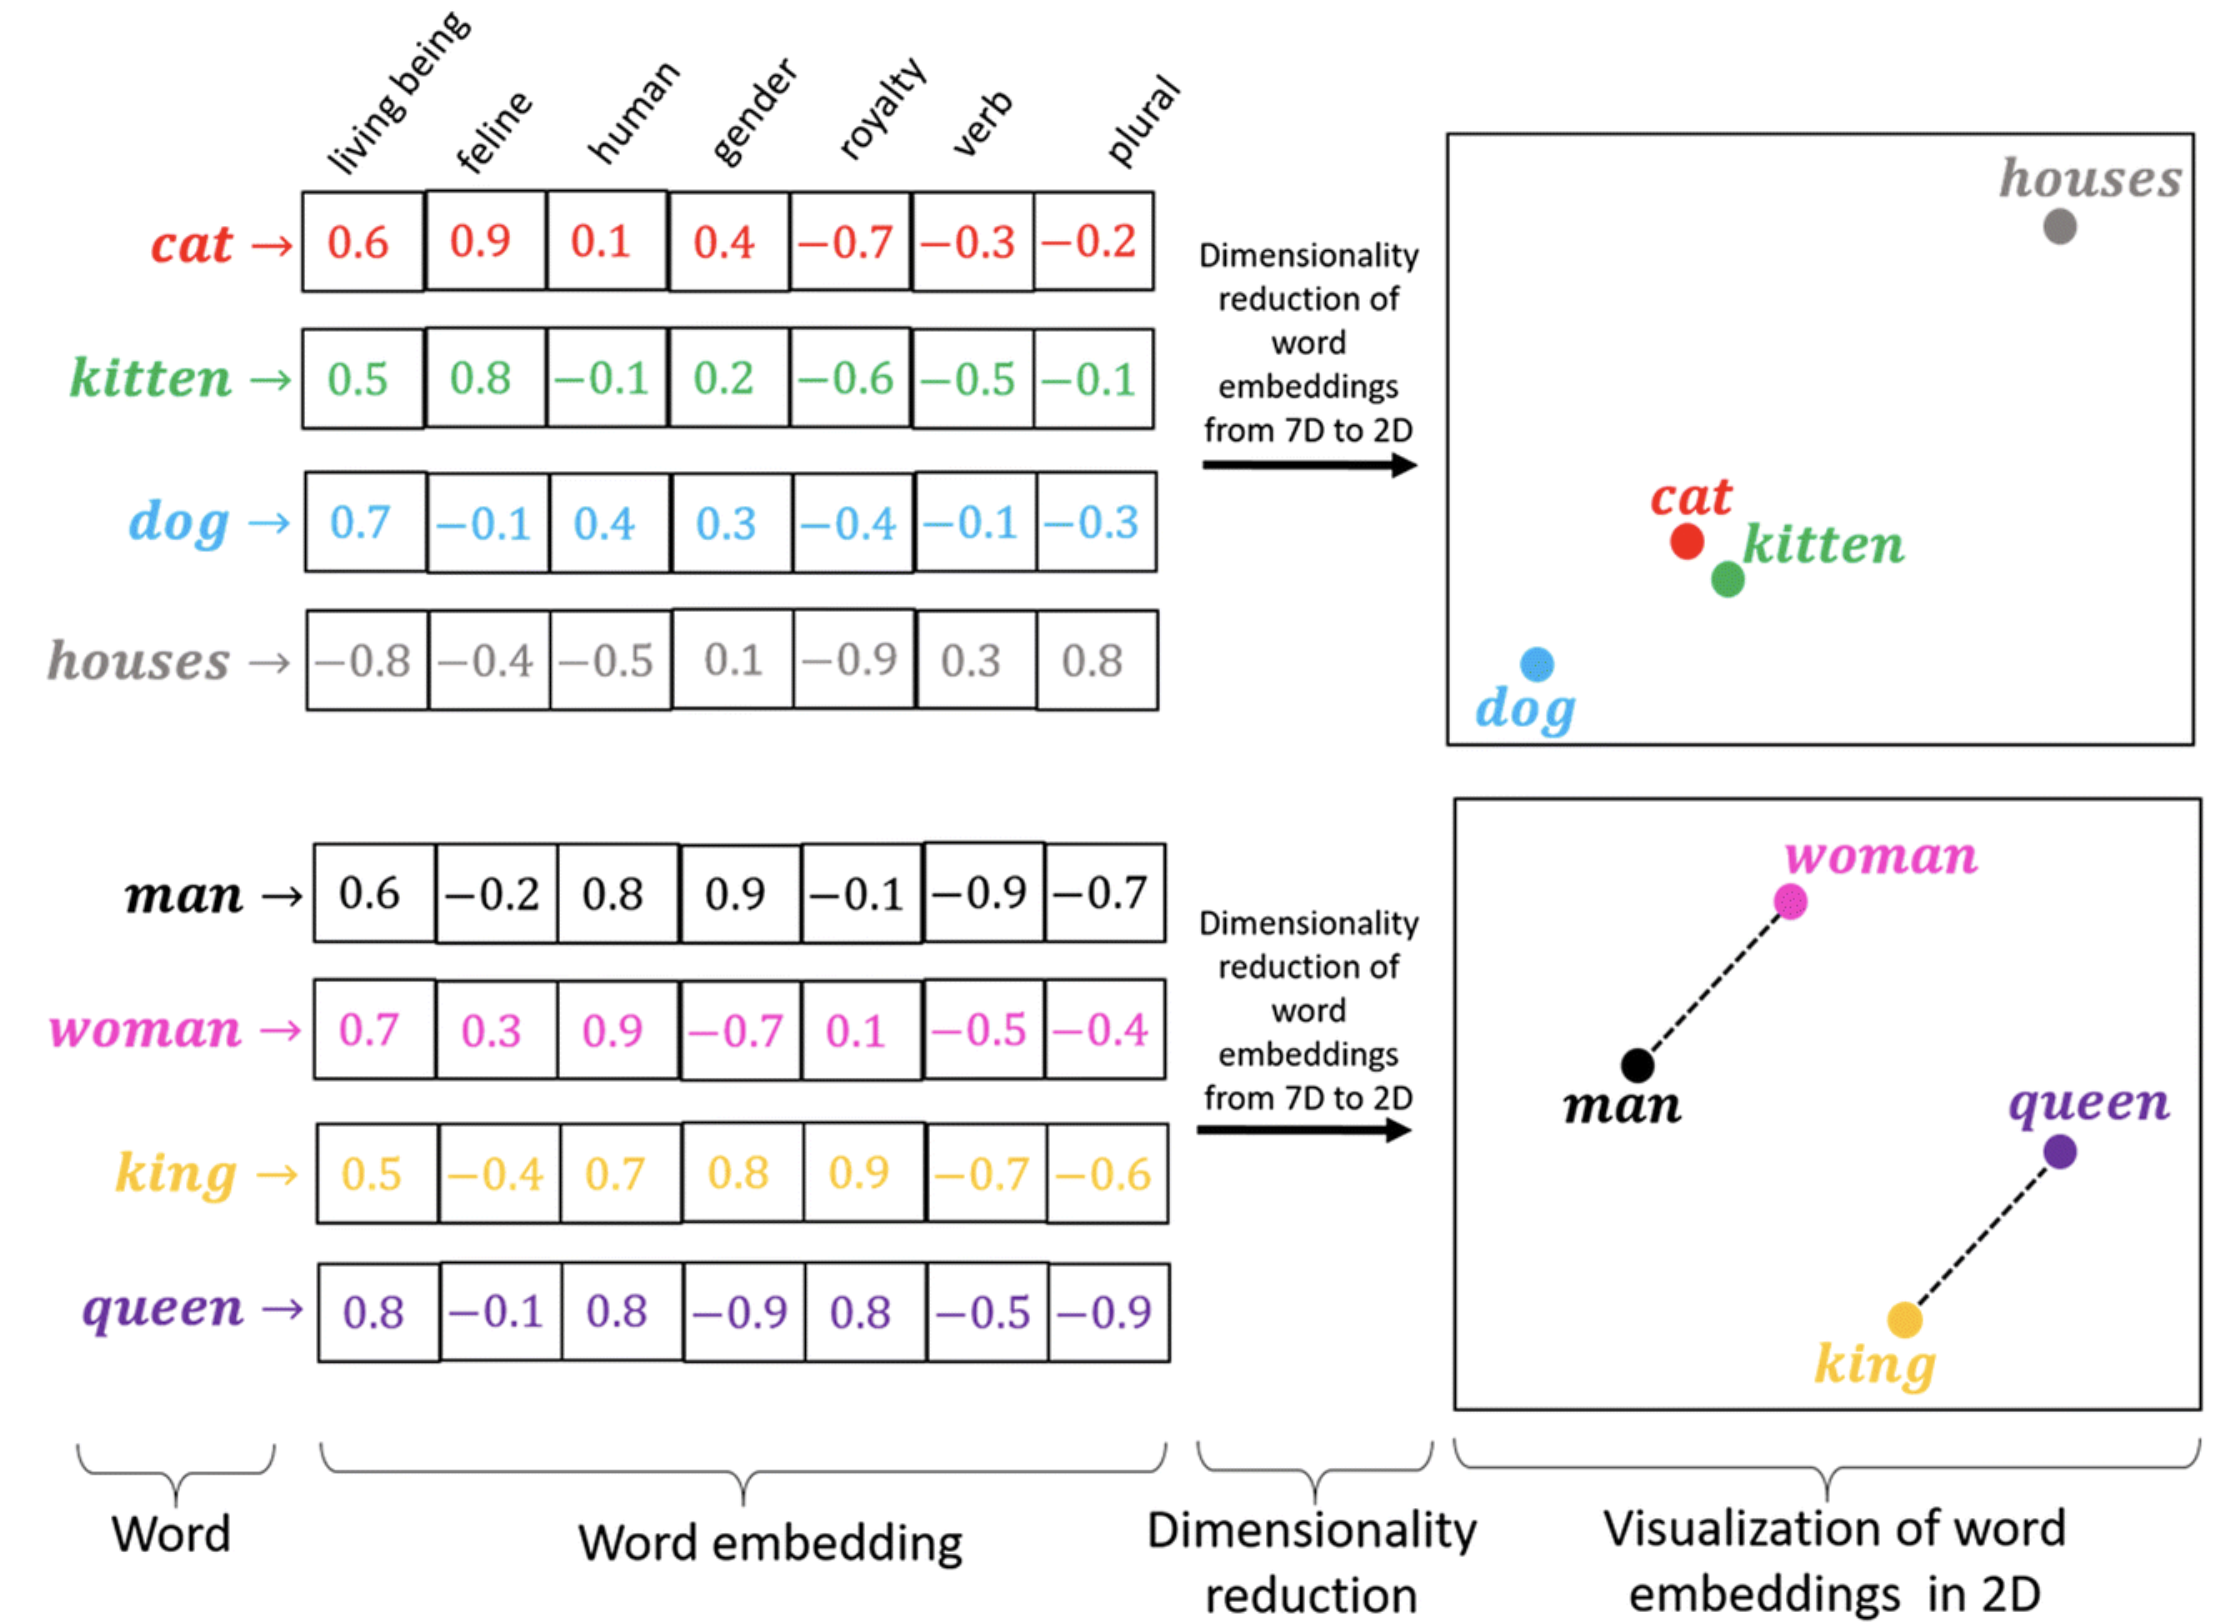

# 1- TF-IDF

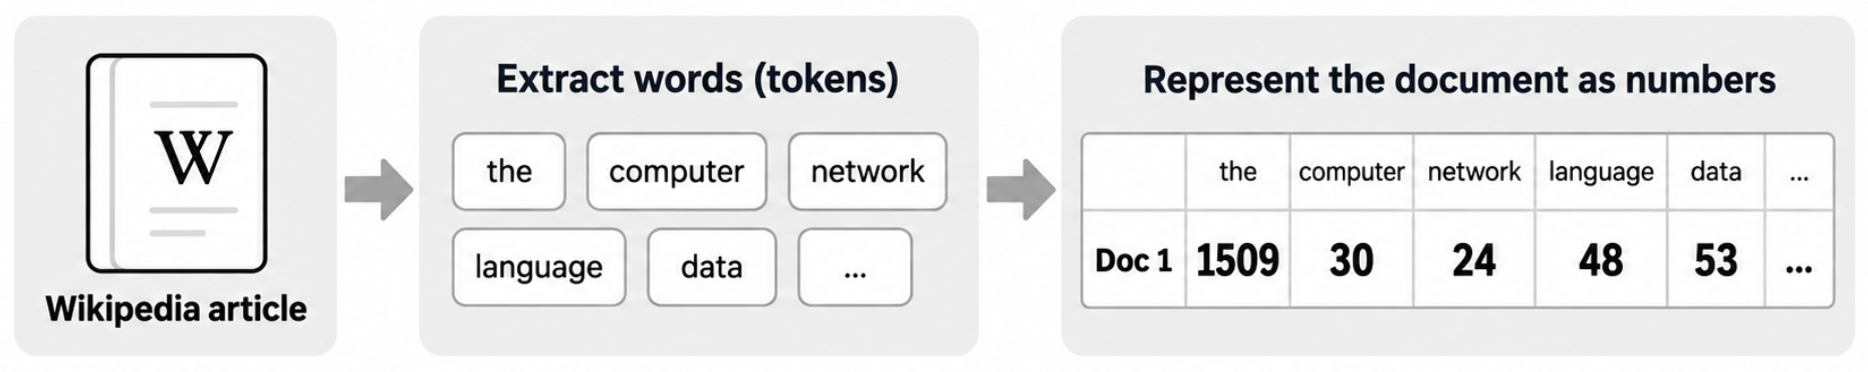

TF-IDF stands for term frequency-inverse document frequency. It is a measure that discounts common words. Used in the fields of information retrieval (IR) and machine learning, that can quantify the importance of words in a document amongst a collection of documents (also known as a corpus).

### Components of TF-IDF

1. **TF (Term Frequency):**  
   Measures how frequently a term appears in a document.


$$ \text{TF}(t, d) = \frac{\text{Number of times term } t \text{ appears in document } d}{\text{Total number of terms in document } d} $$


2. **IDF (Inverse Document Frequency):**  
   Measures how important a term is across all documents. Words that appear in many documents get lower scores.

$$    \text{IDF}(t) = \log \left(\frac{\text{Number of all documents N}}{\text{Number of documents containing the term } t}\right) $$

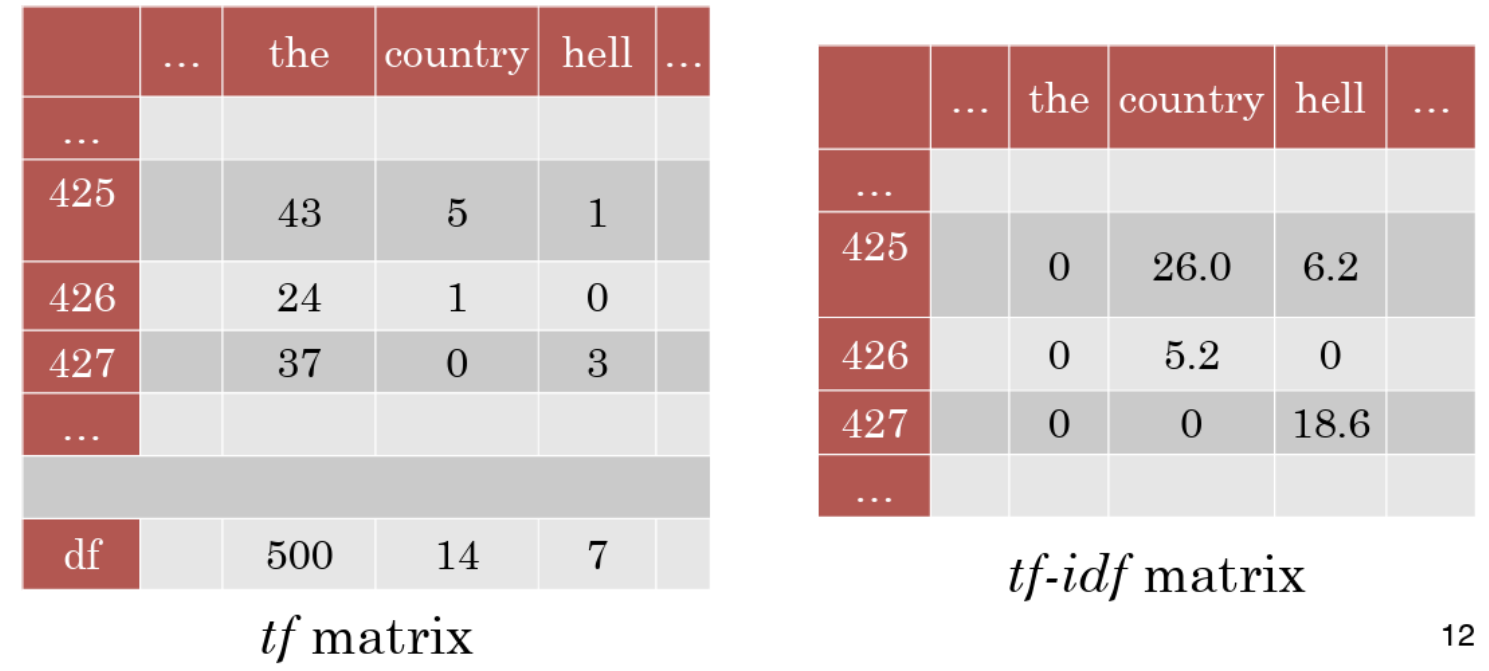

In [2]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

In [3]:
doc_1 = "Data is the oil of the digital economy"
doc_2 = "Data is a new oil"

data = [doc_1, doc_2]


In [4]:
tfidf = TfidfVectorizer()
result = tfidf.fit_transform(data) # returns sparce matrix

In [5]:
df = pd.DataFrame(result.toarray(), columns=tfidf.get_feature_names_out())
df

,data,digital,economy,is,new,of,oil,the
0,0.243777,0.34262,0.34262,0.243777,0.000000,0.34262,0.243777,0.68524
1,0.448321,0.00000,0.00000,0.448321,0.630099,0.00000,0.448321,0.00000


# Cosine similarity

In NLP, Cosine similarity is a metric used to measure how similar the documents are.


$$ \text{cosine similarity} = \frac{A \cdot B}{\|A\| \times \|B\|} $$

Where:  
$ A \cdot B $  = dot product of vectors A and B  
$ \|A\| $ = magnitude (length) of vector A  
$ \|B\| $ =  magnitude (length) of vector B

#### Intuition

- If vectors point in the **same direction**, cosine similarity = **1** (maximum similarity).
- If vectors are **orthogonal (90° apart)**, cosine similarity = **0** (no similarity).

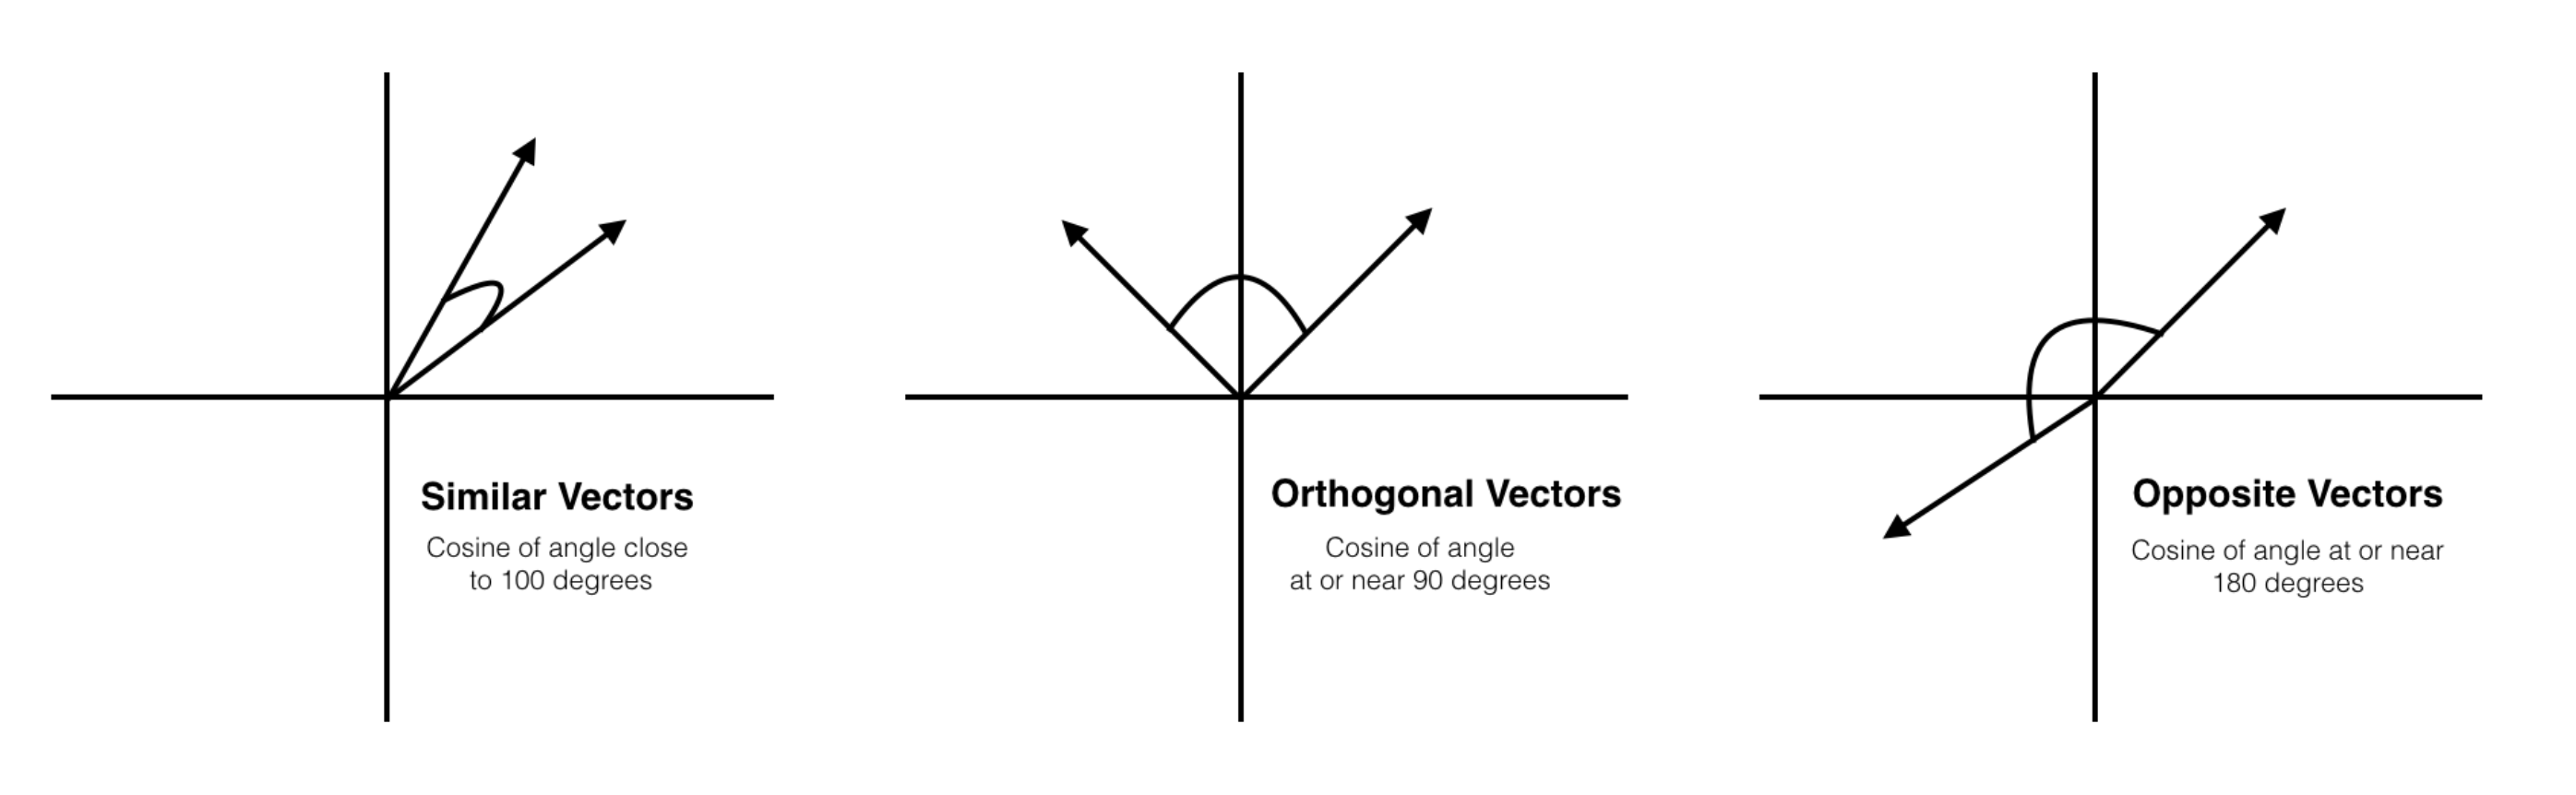

In [6]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [7]:
# Sample text data (replace with your own documents)

doc_1 = "Data is the oil of the digital economy"
doc_2 = "Data is a new oil"

data = [doc_1, doc_2]

In [8]:
tfidf_vectorizer = TfidfVectorizer() # Create a CountVectorizer instance
vector_matrix = tfidf_vectorizer.fit_transform(data) # Fit and transform the documents into numerical vectors

In [9]:
# Calculate the cosine similarity between the documents
cosine_similarity_matrix = cosine_similarity(vector_matrix)

df_cosine = pd.DataFrame(data=cosine_similarity_matrix, index=data, columns=data)

df_cosine

,Data is the oil of the digital economy,Data is a new oil
Data is the oil of the digital economy,1.000000,0.327871
Data is a new oil,0.327871,1.000000


# 2- What is Word2vec?

Word2Vec consists of models for generating word embedding. These models are two-layer neural networks having one input layer, one hidden layer, and one output layer.

Word2Vec utilizes two architectures :
1. CBOW (Continuous Bag of Words)
2. **Skip Gram**
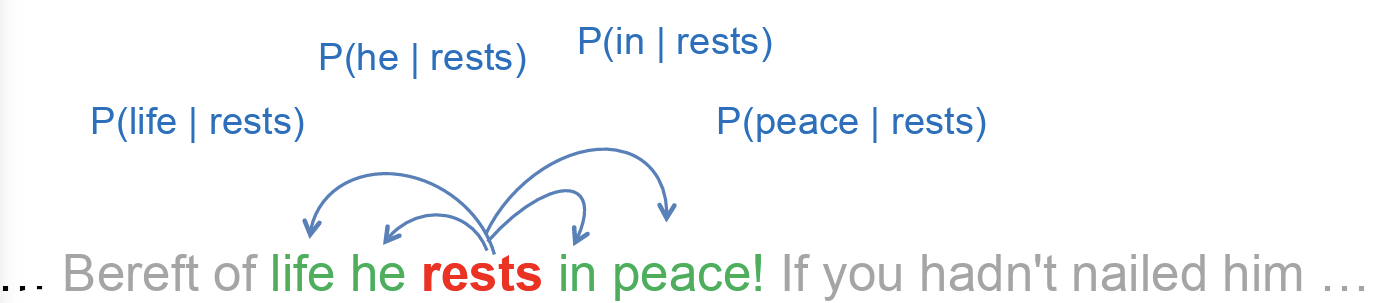


Run this command in terminal to install
> pip install gensim

We will use fake and real news dataset to do our expirament. You can find the dataset here: https://www.kaggle.com/datasets/clmentbisaillon/fake-and-real-news-dataset?select=True.csv


In [10]:
import nltk
for resource in ['punkt_tab', 'stopwords', 'wordnet', 'omw-1.4', 'averaged_perceptron_tagger_eng']:
    nltk.download(resource, quiet=True)
import pandas as pd
import nltk
import numpy as np
import gensim

from nltk.tokenize import word_tokenize

In [11]:
df = pd.read_csv(DATA / 'True.csv').dropna(subset=['text'])
print('News articles:',len(df))
display(df.head())

News articles: 21417


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip their fiscal script",WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congr...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits on Monday: Pentagon,WASHINGTON (Reuters) - Transgender people will be allowed for the first time to enlist...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Mueller do his job',WASHINGTON (Reuters) - The special counsel investigation of links between Russia and P...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat tip-off: NYT,WASHINGTON (Reuters) - Trump campaign adviser George Papadopoulos told an Australian d...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much more' for Amazon shipments,SEATTLE/WASHINGTON (Reuters) - President Donald Trump called on the U.S. Postal Servic...,politicsNews,"December 29, 2017"


In [12]:
# Use a seeded sample of 5,000 real articles for the demonstration.
news_sample = df.sample(n=min(5000,len(df)),random_state=42)
tokens = [word_tokenize(text.lower()) for text in news_sample['text']]

In [13]:
w2v = gensim.models.Word2Vec(tokens, min_count=1, vector_size=100, window=5, sg=1, seed=42, workers=1)

In [14]:
print("Cosine similarity between 'provide' and 'program' - Skip Gram : ",w2v.wv.similarity('provide', 'program'))

Cosine similarity between 'provide' and 'program' - Skip Gram :  0.48480725


In [15]:
print("words that similar to 'program' - Skip Gram : ",w2v.wv.most_similar('program'))

words that similar to 'program' - Skip Gram :  [('programs', 0.777795135974884), ('expansion', 0.7565250992774963), ('medicaid', 0.7469093799591064), ('relief', 0.736809253692627), ('moratorium', 0.7212861776351929), ('freeze', 0.7211013436317444), ('daca', 0.7144243717193604), ('programme', 0.7126159071922302), ('childhood', 0.6961629986763), ('compliance', 0.6957509517669678)]


# Tasks

### Task 1: Cosine Similarity
Use the Cosine Similarity method to determine how similar the following sentences are.

'This is the first document.',  
'This document is the second document.',  
'And this is the third one.',  
'Is this the first document?'  


In [16]:
sentences = ['This is the first document.', 'This document is the second document.',
             'And this is the third one.', 'Is this the first document?']
sentence_vectors = TfidfVectorizer().fit_transform(sentences)
display(pd.DataFrame(cosine_similarity(sentence_vectors),index=['S1','S2','S3','S4'],columns=['S1','S2','S3','S4']))

,S1,S2,S3,S4
S1,1.000000,0.646926,0.307772,1.000000
S2,0.646926,1.000000,0.225240,0.646926
S3,0.307772,0.225240,1.000000,0.307772
S4,1.000000,0.646926,0.307772,1.000000


### Task 2: TF-IDF
Use tf-idf method on the sentences below to determine the important words.

'data science is one of the most important fields of science',  
'this is one of the best data science courses',  
'data scientists analyze data'  


In [17]:
documents = ['data science is one of the most important fields of science',
             'this is one of the best data science courses',
             'data scientists analyze data']
vectorizer = TfidfVectorizer()
features = vectorizer.fit_transform(documents)
weights = pd.DataFrame(features.toarray(),columns=vectorizer.get_feature_names_out(),index=['D1','D2','D3'])
display(weights.T.round(3))
for name,row in weights.iterrows():
    print(name,'top terms:',row[row>0].sort_values(ascending=False).head(5).round(3).to_dict())

,D1,D2,D3
analyze,0.000,0.000,0.543
best,0.000,0.400,0.000
courses,0.000,0.400,0.000
data,0.190,0.236,0.641
fields,0.321,0.000,0.000
important,0.321,0.000,0.000
is,0.244,0.304,0.000
most,0.321,0.000,0.000
of,0.488,0.304,0.000
one,0.244,0.304,0.000


D1 top terms: {'science': 0.488, 'of': 0.488, 'most': 0.321, 'fields': 0.321, 'important': 0.321}
D2 top terms: {'best': 0.4, 'courses': 0.4, 'this': 0.4, 'of': 0.304, 'is': 0.304}
D3 top terms: {'data': 0.641, 'analyze': 0.543, 'scientists': 0.543}


## Word2vec

### Task 3:

Download the Simpsons dataset **(simpsons_script_lines.csv)** and apply the preprocessing procedure.  
Use the **'spoken_words'** column.
```
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[0-9]", '', text)
    text = re.sub(r"[)(,”“.’$-]", '', text)
    return text
```
Create a skip gram Word2Vec model as below.
```
Skip_gram_model = gensim.models.Word2Vec(tokens, min_count = 1, vector_size = 100, window = 5, sg = 1)

In [18]:
import re
simpsons = pd.read_csv(DATA / 'simpsons_script_lines.csv',low_memory=False)
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[0-9]','',text)
    return re.sub(r'[)(,”“.’$-]','',text)
tokens = [word_tokenize(clean_text(text))
          for text in simpsons['spoken_words'].dropna().astype(str)]
tokens = [s for s in tokens if s]
print('Tokenized dialogue lines:',len(tokens))
Skip_gram_model = gensim.models.Word2Vec(tokens,min_count=1,vector_size=100,
                                        window=5,sg=1,seed=42,workers=1)
print('Vocabulary size:',len(Skip_gram_model.wv))

Tokenized dialogue lines: 131839


Vocabulary size: 44175


### Task 4

Use: wv.most_similar() method to :

1.	Find the words similar to “homer”.

2.	Find the words similar to “marge”.

3. Find the words similar to “bart”



In [19]:
for name in ['homer','marge','bart']:
    print(name)
    display(pd.DataFrame(Skip_gram_model.wv.most_similar(name),columns=['Word','Similarity']))

homer


,Word,Similarity
0,abe,0.895622
1,marge,0.853466
2,bart,0.853050
3,eliza,0.844955
4,bartholomew,0.841645
5,grampa,0.827594
6,allison,0.821489
7,kirk,0.820209
8,waylon,0.815407
9,sweetheart,0.815136


marge


,Word,Similarity
0,abe,0.875631
1,homer,0.853466
2,becky,0.843267
3,sweetheart,0.837448
4,sweetie,0.836802
5,midge,0.831098
6,allison,0.823575
7,eliza,0.822297
8,lisa,0.821705
9,luann,0.819698


bart


,Word,Similarity
0,lisa,0.876239
1,milhouse,0.860229
2,eliza,0.855894
3,homer,0.853050
4,abe,0.847308
5,grampa,0.847254
6,allison,0.843849
7,jessica,0.843063
8,sweetie,0.834117
9,maggie,0.823246


### Task 5

Use the wv.doesnt_match() method to :

1.	Find which of 'jimbo', 'milhouse’, and 'kearney’ does not belong to the list.

3.	Find the odd one among "nelson", "bart", and "milhouse".

4.	Find the odd one among ‘homer', 'patty', and ‘selma'.

*Hint: You need to pass the strings as List*

In [20]:
groups = [['jimbo','milhouse','kearney'],['nelson','bart','milhouse'],['homer','patty','selma']]
for group in groups:
    print(group,'->',Skip_gram_model.wv.doesnt_match(group))

['jimbo', 'milhouse', 'kearney'] -> milhouse
['nelson', 'bart', 'milhouse'] -> nelson
['homer', 'patty', 'selma'] -> homer


### Interpretation
The first and fourth documents have cosine similarity 1 because the default TF-IDF tokenizer ignores case, punctuation and word order. TF-IDF highlights terms that are frequent within a document and less common across this corpus; the exact weighting uses scikit-learn's smoothed IDF and L2 normalization. Word2Vec similarity and odd-one-out results are learned from dialogue contexts, so they need not coincide with human judgments about characters or family relationships.